In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df_original = pd.read_csv("diabetic_data.csv")

print("Dataset shape:", df_original.shape)
df_original.head()

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df = df_original.copy()

print("Working dataset shape:", df.shape)

Working dataset shape: (101766, 50)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [6]:
print(df["readmitted"].value_counts(dropna=False))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [7]:
missing_values = (df == "?").sum()

print(missing_values.sort_values(ascending=False))

weight                      98569
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
encounter_id                    0
tolazamide                      0
glyburide                       0
tolbutamide                     0
pioglitazone                    0
rosiglitazone                   0
acarbose                        0
miglitol                        0
troglitazone                    0
citoglipton                     0
examide                         0
acetohexamide                   0
insulin                         0
glyburide-metformin             0
glipizide-metformin             0
glimepiride-pioglitazone        0
metformin-rosiglitazone         0
metformin-pioglitazone          0
change                          0
diabetesMed                     0
glipizide                       0
repaglinide                     0
glimepiride   

In [8]:
print(df.isna().sum().sort_values(ascending=False).head(15))

max_glu_serum    96420
A1Cresult        84748
encounter_id         0
nateglinide          0
glimepiride          0
acetohexamide        0
glipizide            0
glyburide            0
tolbutamide          0
pioglitazone         0
rosiglitazone        0
acarbose             0
miglitol             0
troglitazone         0
tolazamide           0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Total encounters:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

Total encounters: 101766
Unique patients: 71518


In [11]:
df["target"] = (df["readmitted"] == "<30").astype(int)

print(df["target"].value_counts())

target
0    90409
1    11357
Name: count, dtype: int64


In [12]:
target_distribution = df["target"].value_counts(normalize=True) * 100

print(target_distribution)

target
0    88.840084
1    11.159916
Name: proportion, dtype: float64


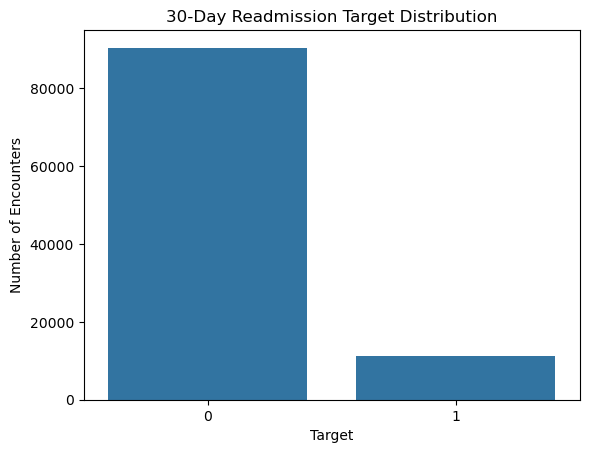

In [13]:
sns.countplot(data=df, x="target")

plt.title("30-Day Readmission Target Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Encounters")
plt.show()

In [14]:
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

print(numeric_columns.tolist())

['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [15]:
df[numeric_columns].describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [16]:
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

target_means = df.groupby("target")[numeric_features].mean()

print(target_means)

        time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
target                                                                          
0               4.349224           42.953644        1.347123        15.911137   
1               4.768249           44.226028        1.280884        16.903143   

        number_outpatient  number_emergency  number_inpatient  \
target                                                          
0                0.360871          0.177803          0.561648   
1                0.436911          0.357313          1.224003   

        number_diagnoses  
target                    
0               7.388667  
1               7.692789  


In [17]:
age_target = df.groupby("age")["target"].agg(
    ["count", "mean"]
)

print(age_target)

          count      mean
age                      
[0-10)      161  0.018634
[10-20)     691  0.057887
[20-30)    1657  0.142426
[30-40)    3775  0.112318
[40-50)    9685  0.106040
[50-60)   17256  0.096662
[60-70)   22483  0.111284
[70-80)   26068  0.117731
[80-90)   17197  0.120835
[90-100)   2793  0.110992


In [18]:
gender_target = df.groupby("gender")["target"].agg(
    ["count", "mean"]
)

print(gender_target)

                 count      mean
gender                          
Female           54708  0.112452
Male             47055  0.110615
Unknown/Invalid      3  0.000000


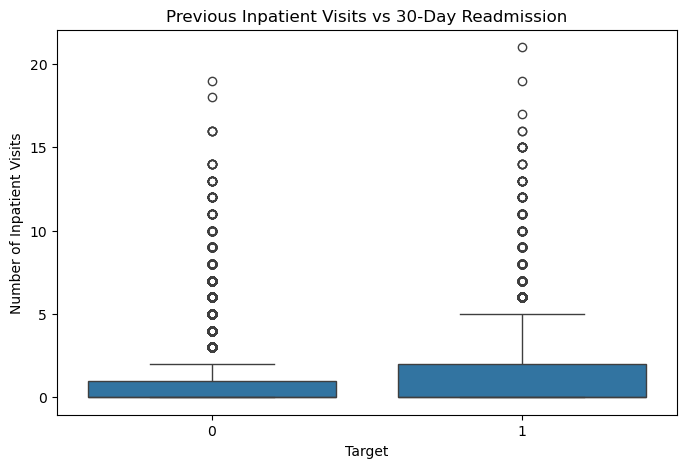

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="number_inpatient"
)

plt.title("Previous Inpatient Visits vs 30-Day Readmission")
plt.xlabel("Target")
plt.ylabel("Number of Inpatient Visits")

plt.show()

In [20]:
df_model = df.copy()

print("Modeling dataset shape:", df_model.shape)

Modeling dataset shape: (101766, 51)


In [21]:
y = df_model["target"]

groups = df_model["patient_nbr"]

print("Target shape:", y.shape)
print("Groups shape:", groups.shape)

Target shape: (101766,)
Groups shape: (101766,)


In [22]:
drop_columns = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "target",
    "discharge_disposition_id",
    "weight"
]

X = df_model.drop(columns=drop_columns)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 45)
y shape: (101766,)


In [23]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 10
Number of categorical features: 35

Numerical features:
['admission_type_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features:
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [24]:
X = X.replace("?", np.nan)

print("Missing values after replacing '?':")
print(X.isna().sum().sort_values(ascending=False).head(15))

Missing values after replacing '?':
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
tolbutamide              0
pioglitazone             0
rosiglitazone            0
acarbose                 0
miglitol                 0
troglitazone             0
tolazamide               0
dtype: int64


In [25]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [26]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [28]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [29]:
train_idx, test_idx = next(
    cv.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (81413, 45)
X_test: (20353, 45)
y_train: (81413,)
y_test: (20353,)


In [30]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
target
0    0.88917
1    0.11083
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.885324
1    0.114676
Name: proportion, dtype: float64


In [31]:
patient_overlap = set(groups_train).intersection(
    set(groups_test)
)

print("Number of patients appearing in both sets:", len(patient_overlap))

Number of patients appearing in both sets: 0


In [32]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

In [33]:
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(y_test, baseline_pred, zero_division=0)
baseline_recall = recall_score(y_test, baseline_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("Baseline Results")
print("----------------")
print("Accuracy :", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall   :", baseline_recall)
print("F1 Score :", baseline_f1)

Baseline Results
----------------
Accuracy : 0.8853240308554021
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0


In [34]:
baseline_cm = confusion_matrix(y_test, baseline_pred)

print(baseline_cm)

[[18019     0]
 [ 2334     0]]


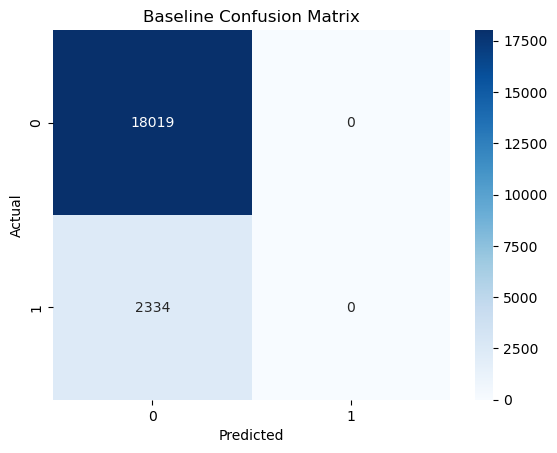

In [35]:
sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [36]:
class_weight="balanced"

In [37]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

In [38]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [39]:
logistic_pred = logistic_model.predict(X_test)

logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

In [40]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)
print("ROC-AUC  :", logistic_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.6454576720876529
Precision: 0.16752928357395805
Recall   : 0.5269922879177378
F1 Score : 0.2542372881355932
ROC-AUC  : 0.6320059759827923


In [41]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_pred
)

print(logistic_cm)

[[11907  6112]
 [ 1104  1230]]


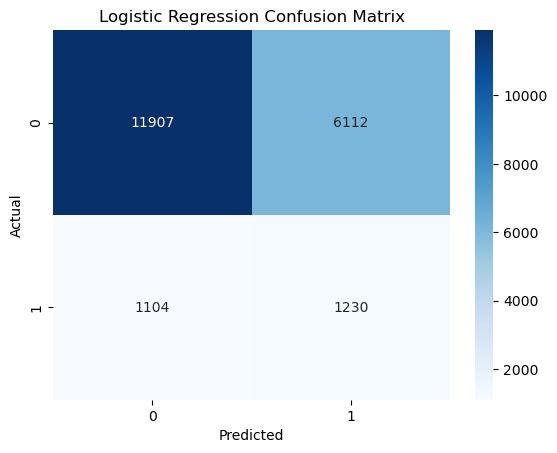

In [42]:
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [43]:
print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=[
            "No 30-Day Readmission",
            "30-Day Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

No 30-Day Readmission       0.92      0.66      0.77     18019
   30-Day Readmission       0.17      0.53      0.25      2334

             accuracy                           0.65     20353
            macro avg       0.54      0.59      0.51     20353
         weighted avg       0.83      0.65      0.71     20353



In [44]:
from sklearn.tree import DecisionTreeClassifier

In [45]:
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10
    ))
])

In [46]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [47]:
dt_pred = decision_tree_model.predict(X_test)

dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

In [48]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)
print("ROC-AUC  :", dt_auc)

Decision Tree Results
---------------------
Accuracy : 0.5743133690365056
Precision: 0.1495792736935341
Recall   : 0.578834618680377
F1 Score : 0.2377265528770016
ROC-AUC  : 0.6000785707821596


In [49]:
dt_cm = confusion_matrix(y_test, dt_pred)

print(dt_cm)

[[10338  7681]
 [  983  1351]]


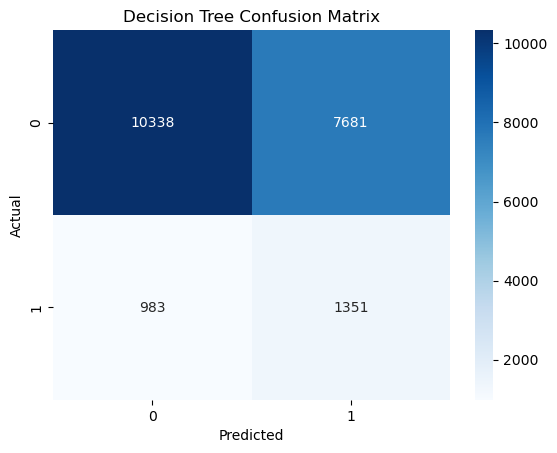

In [50]:
sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [51]:
from sklearn.ensemble import RandomForestClassifier

In [52]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [53]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [54]:
rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [55]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_auc)

Random Forest Results
---------------------
Accuracy : 0.6489952341178205
Precision: 0.17162752594210814
Recall   : 0.538560411311054
F1 Score : 0.2603023400289915
ROC-AUC  : 0.6369448976855954


In [56]:
rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

[[11952  6067]
 [ 1077  1257]]


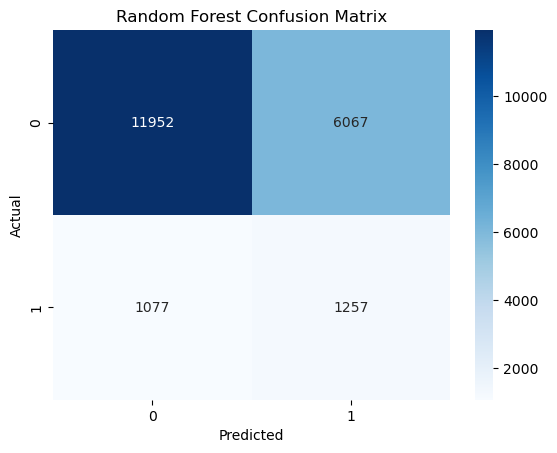

In [57]:
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [58]:
from sklearn.svm import LinearSVC

In [59]:
svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

In [60]:
svm_model.fit(X_train, y_train)

print("Linear SVM training completed.")

Linear SVM training completed.


In [61]:
svm_pred = svm_model.predict(X_test)

In [62]:
svm_score = svm_model.decision_function(X_test)

In [63]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)
svm_auc = roc_auc_score(y_test, svm_score)

print("Linear SVM Results")
print("------------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)
print("ROC-AUC  :", svm_auc)

Linear SVM Results
------------------
Accuracy : 0.6415761804156636
Precision: 0.16556559255763786
Recall   : 0.5261353898886033
F1 Score : 0.2518716029125218
ROC-AUC  : 0.6291282414311505


In [64]:
svm_cm = confusion_matrix(y_test, svm_pred)

print(svm_cm)

[[11830  6189]
 [ 1106  1228]]


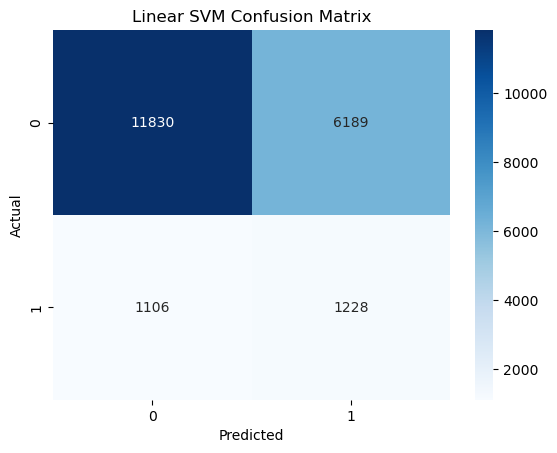

In [65]:
sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [66]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Linear SVM"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy
    ],
    "Precision": [
        baseline_precision,
        logistic_precision,
        dt_precision,
        rf_precision,
        svm_precision
    ],
    "Recall": [
        baseline_recall,
        logistic_recall,
        dt_recall,
        rf_recall,
        svm_recall
    ],
    "F1 Score": [
        baseline_f1,
        logistic_f1,
        dt_f1,
        rf_f1,
        svm_f1
    ],
    "ROC-AUC": [
        np.nan,
        logistic_auc,
        dt_auc,
        rf_auc,
        svm_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline,0.885324,0.000000,0.000000,0.000000,NaN
1,Logistic Regression,0.645458,0.167529,0.526992,0.254237,0.632006
2,Decision Tree,0.574313,0.149579,0.578835,0.237727,0.600079
3,Random Forest,0.648995,0.171628,0.538560,0.260302,0.636945
4,Linear SVM,0.641576,0.165566,0.526135,0.251872,0.629128


In [67]:
results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline,0.8853,0.0000,0.0000,0.0000,NaN
1,Logistic Regression,0.6455,0.1675,0.5270,0.2542,0.6320
2,Decision Tree,0.5743,0.1496,0.5788,0.2377,0.6001
3,Random Forest,0.6490,0.1716,0.5386,0.2603,0.6369
4,Linear SVM,0.6416,0.1656,0.5261,0.2519,0.6291


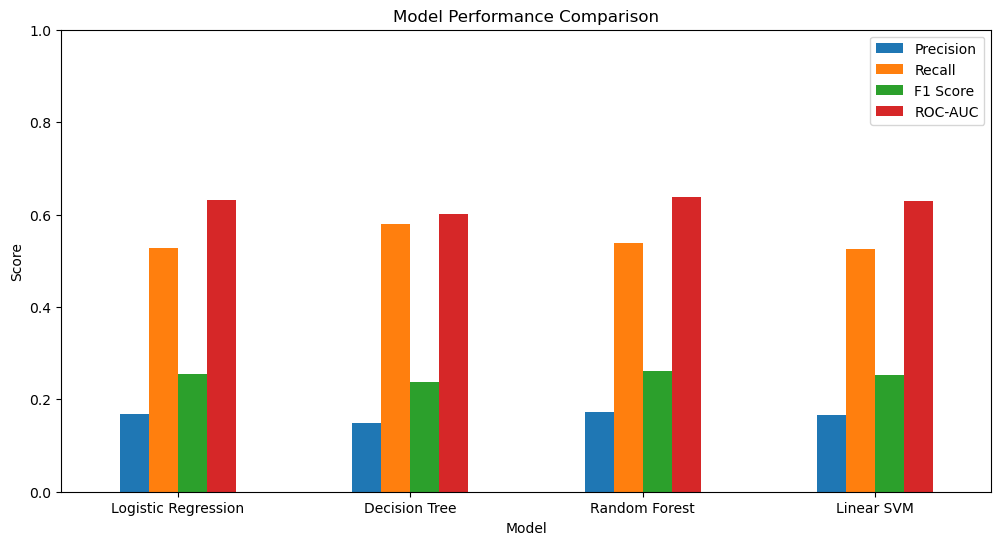

In [68]:
model_metrics = results[
    results["Model"] != "Baseline"
].set_index("Model")

model_metrics[[
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.show()

In [69]:
from sklearn.metrics import roc_curve

In [70]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, logistic_prob)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_score)

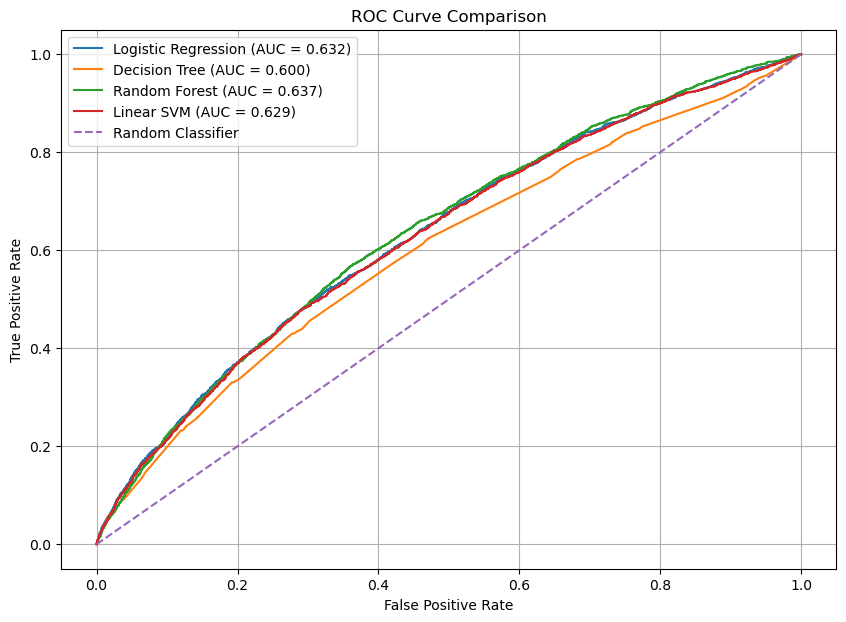

In [71]:
plt.figure(figsize=(10, 7))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    dt_fpr,
    dt_tpr,
    label=f"Decision Tree (AUC = {dt_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    svm_fpr,
    svm_tpr,
    label=f"Linear SVM (AUC = {svm_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [72]:
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

importances = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(20)

,Feature,Importance
8,num__number_inpatient,0.213462
7,num__number_emergency,0.047690
9,num__number_diagnoses,0.042049
5,num__num_medications,0.041906
2,num__time_in_hospital,0.034764
6,num__number_outpatient,0.024036
3,num__num_lab_procedures,0.023385
496,cat__diag_2_250,0.013788
402,cat__diag_1_786,0.013593
1242,cat__insulin_Down,0.013234


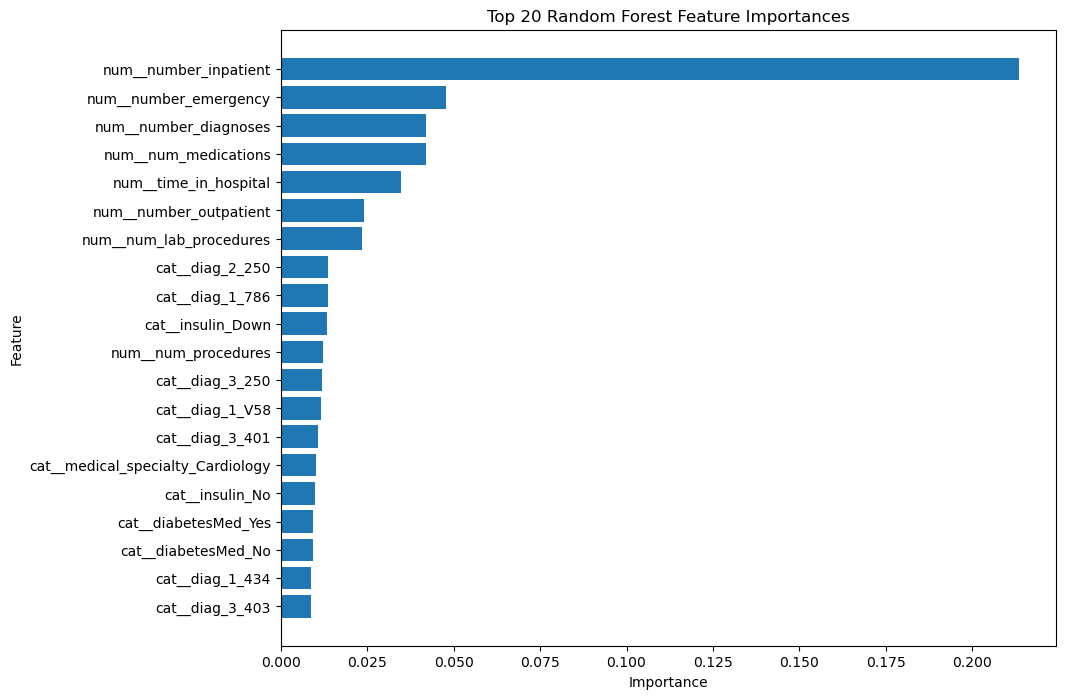

In [73]:
top_features = feature_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Feature Importances")

plt.show()

In [74]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    
    predictions = (rf_prob >= threshold).astype(int)
    
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.20,0.114676,1.000000,0.205757
1,0.25,0.114676,1.000000,0.205757
2,0.30,0.114699,1.000000,0.205793
3,0.35,0.114933,0.999143,0.206153
4,0.40,0.117569,0.984576,0.210055
5,0.45,0.130712,0.886033,0.227816
6,0.50,0.171628,0.538560,0.260302


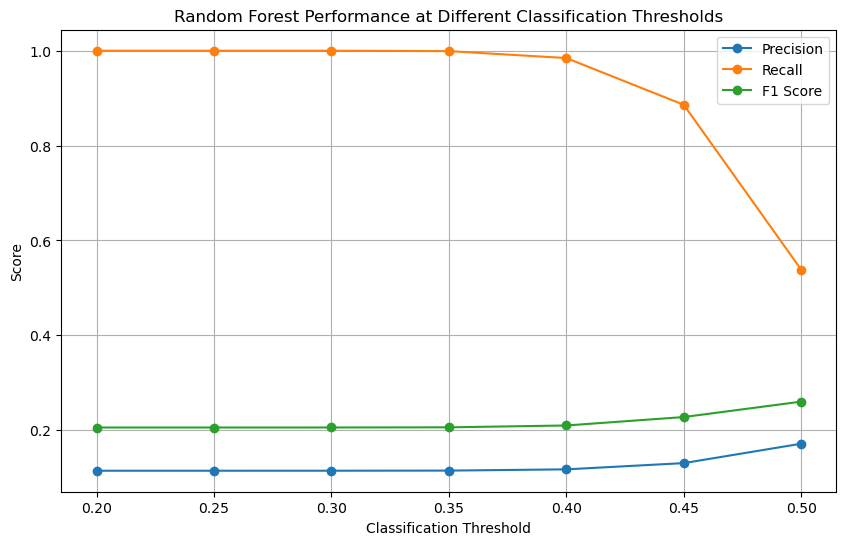

In [75]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest Performance at Different Classification Thresholds")

plt.legend()
plt.grid(True)

plt.show()

In [76]:
from sklearn.model_selection import cross_validate, StratifiedGroupKFold

In [77]:
cv_5fold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [78]:
rf_cv_results = cross_validate(
    random_forest_model,
    X,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

In [79]:
rf_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": rf_cv_results["test_accuracy"],
    "Precision": rf_cv_results["test_precision"],
    "Recall": rf_cv_results["test_recall"],
    "F1": rf_cv_results["test_f1"],
    "ROC-AUC": rf_cv_results["test_roc_auc"]
})

rf_cv_df

,Fold,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,0.648995,0.171628,0.538560,0.260302,0.636945
1,2,0.643745,0.154521,0.531825,0.239465,0.641201
2,3,0.634711,0.168596,0.560017,0.259168,0.643637
3,4,0.637794,0.164852,0.551800,0.253862,0.645116
4,5,0.634254,0.163981,0.552781,0.252931,0.645009


In [80]:
print("Random Forest 5-Fold Cross-Validation")
print("-------------------------------------")

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]:
    print(
        f"{metric}: "
        f"{rf_cv_df[metric].mean():.4f} "
        f"+/- {rf_cv_df[metric].std():.4f}"
    )

Random Forest 5-Fold Cross-Validation
-------------------------------------
Accuracy: 0.6399 +/- 0.0063
Precision: 0.1647 +/- 0.0065
Recall: 0.5470 +/- 0.0115
F1: 0.2531 +/- 0.0083
ROC-AUC: 0.6424 +/- 0.0034


In [81]:
lr_cv_results = cross_validate(
    logistic_model,
    X,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("Logistic Regression")
print("-------------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = lr_cv_results[f"test_{metric}"]
    print(f"{metric.upper():10}: {scores.mean():.4f} +/- {scores.std():.4f}")

Logistic Regression
-------------------
ACCURACY  : 0.6400 +/- 0.0047
PRECISION : 0.1633 +/- 0.0051
RECALL    : 0.5400 +/- 0.0132
F1        : 0.2507 +/- 0.0068
ROC_AUC   : 0.6341 +/- 0.0027


In [82]:
dt_cv_results = cross_validate(
    decision_tree_model,
    X,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("Decision Tree")
print("-------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = dt_cv_results[f"test_{metric}"]
    print(f"{metric.upper():10}: {scores.mean():.4f} +/- {scores.std():.4f}")

Decision Tree
-------------
ACCURACY  : 0.6122 +/- 0.0370
PRECISION : 0.1541 +/- 0.0062
RECALL    : 0.5483 +/- 0.0412
F1        : 0.2401 +/- 0.0058
ROC_AUC   : 0.6132 +/- 0.0069


In [83]:
svm_cv_results = cross_validate(
    svm_model,
    X,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("Linear SVM")
print("----------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = svm_cv_results[f"test_{metric}"]
    print(f"{metric.upper():10}: {scores.mean():.4f} +/- {scores.std():.4f}")

Linear SVM
----------
ACCURACY  : 0.6352 +/- 0.0046
PRECISION : 0.1613 +/- 0.0050
RECALL    : 0.5403 +/- 0.0124
F1        : 0.2484 +/- 0.0066
ROC_AUC   : 0.6305 +/- 0.0028


In [84]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Linear SVM"
    ],

    "Accuracy Mean": [
        lr_cv_results["test_accuracy"].mean(),
        dt_cv_results["test_accuracy"].mean(),
        rf_cv_results["test_accuracy"].mean(),
        svm_cv_results["test_accuracy"].mean()
    ],

    "Accuracy Std": [
        lr_cv_results["test_accuracy"].std(),
        dt_cv_results["test_accuracy"].std(),
        rf_cv_results["test_accuracy"].std(),
        svm_cv_results["test_accuracy"].std()
    ],

    "Precision Mean": [
        lr_cv_results["test_precision"].mean(),
        dt_cv_results["test_precision"].mean(),
        rf_cv_results["test_precision"].mean(),
        svm_cv_results["test_precision"].mean()
    ],

    "Recall Mean": [
        lr_cv_results["test_recall"].mean(),
        dt_cv_results["test_recall"].mean(),
        rf_cv_results["test_recall"].mean(),
        svm_cv_results["test_recall"].mean()
    ],

    "F1 Mean": [
        lr_cv_results["test_f1"].mean(),
        dt_cv_results["test_f1"].mean(),
        rf_cv_results["test_f1"].mean(),
        svm_cv_results["test_f1"].mean()
    ],

    "ROC-AUC Mean": [
        lr_cv_results["test_roc_auc"].mean(),
        dt_cv_results["test_roc_auc"].mean(),
        rf_cv_results["test_roc_auc"].mean(),
        svm_cv_results["test_roc_auc"].mean()
    ]
})

cv_comparison.round(4)

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean
0,Logistic Regression,0.6400,0.0047,0.1633,0.5400,0.2507,0.6341
1,Decision Tree,0.6122,0.0370,0.1541,0.5483,0.2401,0.6132
2,Random Forest,0.6399,0.0057,0.1647,0.5470,0.2531,0.6424
3,Linear SVM,0.6352,0.0046,0.1613,0.5403,0.2484,0.6305


In [85]:
reduced_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "age",
    "gender",
    "admission_type_id",
    "admission_source_id",
    "diag_1",
    "diag_2",
    "diag_3"
]
X_reduced = df_model[reduced_features].copy()

print("Reduced feature shape:", X_reduced.shape)
print("\nReduced features:")
print(reduced_features)

Reduced feature shape: (101766, 15)

Reduced features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age', 'gender', 'admission_type_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3']


In [86]:
print("X_reduced:", X_reduced.shape)
print("y:", y.shape)
print("groups:", groups.shape)

print("\nTarget distribution:")
print(y.value_counts())

X_reduced: (101766, 15)
y: (101766,)
groups: (101766,)

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [88]:
reduced_numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

reduced_categorical_features = [
    "age",
    "gender",
    "admission_type_id",
    "admission_source_id",
    "diag_1",
    "diag_2",
    "diag_3"
]

In [89]:
reduced_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

reduced_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

In [90]:
reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            reduced_numeric_pipeline,
            reduced_numeric_features
        ),
        (
            "cat",
            reduced_categorical_pipeline,
            reduced_categorical_features
        )
    ]
)

print("Reduced preprocessing pipeline created.")

Reduced preprocessing pipeline created.


In [91]:
reduced_rf_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Reduced Random Forest created.")

Reduced Random Forest created.


In [92]:
reduced_rf_cv_results = cross_validate(
    reduced_rf_model,
    X_reduced,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

In [93]:
print("Reduced Random Forest 5-Fold Cross-Validation")
print("----------------------------------------------")

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]:
    scores = reduced_rf_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

Reduced Random Forest 5-Fold Cross-Validation
----------------------------------------------
ACCURACY  : 0.6386 +/- 0.0078
PRECISION : 0.1648 +/- 0.0059
RECALL    : 0.5500 +/- 0.0108
F1        : 0.2535 +/- 0.0065
ROC_AUC   : 0.6399 +/- 0.0033


In [94]:
# Train reduced Random Forest on the same train/test split

reduced_rf_model.fit(
    X_reduced.iloc[train_idx],
    y.iloc[train_idx]
)

reduced_rf_prob = reduced_rf_model.predict_proba(
    X_reduced.iloc[test_idx]
)[:, 1]

reduced_rf_pred = (
    reduced_rf_prob >= 0.5
).astype(int)

print("Reduced Random Forest trained.")

Reduced Random Forest trained.


In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Reduced Random Forest - Held-Out Test Results")
print("-----------------------------------------------")

print("Accuracy :", accuracy_score(
    y.iloc[test_idx],
    reduced_rf_pred
))

print("Precision:", precision_score(
    y.iloc[test_idx],
    reduced_rf_pred
))

print("Recall   :", recall_score(
    y.iloc[test_idx],
    reduced_rf_pred
))

print("F1 Score :", f1_score(
    y.iloc[test_idx],
    reduced_rf_pred
))

print("ROC-AUC  :", roc_auc_score(
    y.iloc[test_idx],
    reduced_rf_prob
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y.iloc[test_idx],
    reduced_rf_pred
))

Reduced Random Forest - Held-Out Test Results
-----------------------------------------------
Accuracy : 0.6531715226256571
Precision: 0.17201166180758018
Recall   : 0.5308483290488432
F1 Score : 0.2598301352626612
ROC-AUC  : 0.6344980850214614

Confusion Matrix:
[[12055  5964]
 [ 1095  1239]]


In [96]:
reduced_features_12 = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "age",
    "gender",
    "admission_type_id",
    "admission_source_id"
]

X_reduced_12 = df_model[reduced_features_12].copy()

print("12-feature shape:", X_reduced_12.shape)

print("\n12 features:")
print(reduced_features_12)

12-feature shape: (101766, 12)

12 features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age', 'gender', 'admission_type_id', 'admission_source_id']


In [97]:
reduced_12_numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

reduced_12_categorical_features = [
    "age",
    "gender",
    "admission_type_id",
    "admission_source_id"
]

In [98]:
reduced_12_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

reduced_12_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

In [99]:
reduced_12_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            reduced_12_numeric_pipeline,
            reduced_12_numeric_features
        ),
        (
            "cat",
            reduced_12_categorical_pipeline,
            reduced_12_categorical_features
        )
    ]
)

print("12-feature preprocessing pipeline created.")

12-feature preprocessing pipeline created.


In [100]:
reduced_12_rf_model = Pipeline(steps=[
    ("preprocessor", reduced_12_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("12-feature Random Forest created.")

12-feature Random Forest created.


In [101]:
reduced_12_rf_cv_results = cross_validate(
    reduced_12_rf_model,
    X_reduced_12,
    y,
    groups=groups,
    cv=cv_5fold,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

In [102]:
print("12-Feature Random Forest 5-Fold Cross-Validation")
print("------------------------------------------------")

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]:
    scores = reduced_12_rf_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

12-Feature Random Forest 5-Fold Cross-Validation
------------------------------------------------
ACCURACY  : 0.6921 +/- 0.0066
PRECISION : 0.1714 +/- 0.0054
RECALL    : 0.4589 +/- 0.0220
F1        : 0.2494 +/- 0.0077
ROC_AUC   : 0.6356 +/- 0.0081


In [103]:
# Train the 12-feature Random Forest on the same training set

reduced_12_rf_model.fit(
    X_reduced_12.iloc[train_idx],
    y.iloc[train_idx]
)

reduced_12_rf_prob = reduced_12_rf_model.predict_proba(
    X_reduced_12.iloc[test_idx]
)[:, 1]

reduced_12_rf_pred = (
    reduced_12_rf_prob >= 0.5
).astype(int)

print("12-feature Random Forest trained.")

12-feature Random Forest trained.


In [104]:
print("12-Feature Random Forest - Held-Out Test Results")
print("--------------------------------------------------")

print("Accuracy :", accuracy_score(
    y.iloc[test_idx],
    reduced_12_rf_pred
))

print("Precision:", precision_score(
    y.iloc[test_idx],
    reduced_12_rf_pred
))

print("Recall   :", recall_score(
    y.iloc[test_idx],
    reduced_12_rf_pred
))

print("F1 Score :", f1_score(
    y.iloc[test_idx],
    reduced_12_rf_pred
))

print("ROC-AUC  :", roc_auc_score(
    y.iloc[test_idx],
    reduced_12_rf_prob
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y.iloc[test_idx],
    reduced_12_rf_pred
))

12-Feature Random Forest - Held-Out Test Results
--------------------------------------------------
Accuracy : 0.7007320788090208
Precision: 0.1719923170944648
Recall   : 0.4220222793487575
F1 Score : 0.24438655253690608
ROC-AUC  : 0.6207204496558022

Confusion Matrix:
[[13277  4742]
 [ 1349   985]]


In [105]:
print("Final features:")
print(reduced_features)

print("\nNumber of features:", len(reduced_features))

Final features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age', 'gender', 'admission_type_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3']

Number of features: 15


In [106]:
# Final 15-feature Random Forest

final_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Final 15-feature Random Forest created.")

Final 15-feature Random Forest created.


In [107]:
final_model.fit(
    X_reduced,
    y
)

print("Final model trained successfully.")

Final model trained successfully.


In [108]:
ids_mapping = pd.read_csv("IDS_mapping.csv")

print("Shape:", ids_mapping.shape)

print("\nColumns:")
print(ids_mapping.columns.tolist())

print("\nFirst 20 rows:")
display(ids_mapping.head(20))

Shape: (67, 2)

Columns:
['admission_type_id', 'description']

First 20 rows:


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [109]:
pd.set_option("display.max_rows", 100)

display(ids_mapping)

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [110]:
print("Unique diag_1:", df["diag_1"].nunique())
print("Unique diag_2:", df["diag_2"].nunique())
print("Unique diag_3:", df["diag_3"].nunique())

Unique diag_1: 717
Unique diag_2: 749
Unique diag_3: 790


In [111]:
# Find the admission_source_id section in IDS_mapping

mapping = ids_mapping.copy()

for i, value in enumerate(mapping["admission_type_id"].astype(str)):
    if value == "admission_source_id":
        print("admission_source_id section starts at row:", i)
        display(mapping.iloc[i:i+25])
        break

admission_source_id section starts at row: 41


,admission_type_id,description
41,admission_source_id,description
42,1,Physician Referral
43,2,Clinic Referral
44,3,HMO Referral
45,4,Transfer from a hospital
46,5,Transfer from a Skilled Nursing Facility (SNF)
47,6,Transfer from another health care facility
48,7,Emergency Room
49,8,Court/Law Enforcement
50,9,Not Available


In [112]:
print("AGE VALUES")
print(sorted(df_model["age"].dropna().unique()))

print("\nGENDER VALUES")
print(sorted(df_model["gender"].dropna().unique()))

print("\nADMISSION TYPE IDs")
print(sorted(df_model["admission_type_id"].dropna().unique()))

print("\nADMISSION SOURCE IDs")
print(sorted(df_model["admission_source_id"].dropna().unique()))

AGE VALUES
['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']

GENDER VALUES
['Female', 'Male', 'Unknown/Invalid']

ADMISSION TYPE IDs
[1, 2, 3, 4, 5, 6, 7, 8]

ADMISSION SOURCE IDs
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 17, 20, 22, 25]


In [113]:
print("TOP DIAG_1 CODES")
print(df_model["diag_1"].value_counts(dropna=False).head(20))

print("\nTOP DIAG_2 CODES")
print(df_model["diag_2"].value_counts(dropna=False).head(20))

print("\nTOP DIAG_3 CODES")
print(df_model["diag_3"].value_counts(dropna=False).head(20))

TOP DIAG_1 CODES
diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
599      1595
584      1520
V57      1207
250.6    1183
518      1115
Name: count, dtype: int64

TOP DIAG_2 CODES
diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
250.01    1523
285       1520
780       1491
425       1434
682       1433
Name: count, dtype: int64

TOP DIAG_3 CODES
diag_3
250       11555
401        8289
276        5175
428        4577
427        3955
414        3664
496        2605
403        2357
585        1992
272        1969
599        1941
?          1423
V45        1389
250.02     1369
707        1360
780        1334
285        1200
425        1136
250.6 

In [114]:
# Age options
age_options = sorted(
    df_model["age"].dropna().unique().tolist()
)

# Gender options
gender_options = sorted(
    df_model["gender"].dropna().unique().tolist()
)

# Admission type options
admission_type_options = sorted(
    df_model["admission_type_id"].dropna().unique().tolist()
)

# Admission source options
admission_source_options = sorted(
    df_model["admission_source_id"].dropna().unique().tolist()
)

# Diagnosis options
diag_1_options = sorted(
    df_model["diag_1"].dropna().unique().tolist()
)

diag_2_options = sorted(
    df_model["diag_2"].dropna().unique().tolist()
)

diag_3_options = sorted(
    df_model["diag_3"].dropna().unique().tolist()
)

print("Age options:", len(age_options))
print("Gender options:", len(gender_options))
print("Admission type options:", len(admission_type_options))
print("Admission source options:", len(admission_source_options))
print("Diag 1 options:", len(diag_1_options))
print("Diag 2 options:", len(diag_2_options))
print("Diag 3 options:", len(diag_3_options))

Age options: 10
Gender options: 3
Admission type options: 8
Admission source options: 17
Diag 1 options: 717
Diag 2 options: 749
Diag 3 options: 790


In [115]:
# Create one sample patient for testing

patient = pd.DataFrame({
    "time_in_hospital": [4],
    "num_lab_procedures": [40],
    "num_procedures": [1],
    "num_medications": [10],
    "number_outpatient": [0],
    "number_emergency": [0],
    "number_inpatient": [1],
    "number_diagnoses": [5],
    "age": ["[60-70)"],
    "gender": ["Female"],
    "admission_type_id": [1],
    "admission_source_id": [7],
    "diag_1": ["428"],
    "diag_2": ["276"],
    "diag_3": ["250"]
})

patient

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age,gender,admission_type_id,admission_source_id,diag_1,diag_2,diag_3
0,4,40,1,10,0,0,1,5,[60-70),Female,1,7,428,276,250


In [116]:
# Predict the class
prediction = final_model.predict(patient)

# Predict probability
probability = final_model.predict_proba(patient)

print("Prediction:", prediction[0])
print("Probability:", probability[0])

Prediction: 0
Probability: [0.50025207 0.49974793]


In [117]:
print(patient.to_string(index=False))

 time_in_hospital  num_lab_procedures  num_procedures  num_medications  number_outpatient  number_emergency  number_inpatient  number_diagnoses     age gender  admission_type_id  admission_source_id diag_1 diag_2 diag_3
                4                  40               1               10                  0                 0                 1                 5 [60-70) Female                  1                    7    428    276    250


In [118]:
# Get prediction
prediction = final_model.predict(patient)[0]

# Get probability of class 1
risk_probability = final_model.predict_proba(patient)[0][1]

print("Prediction:", prediction)
print(f"30-day readmission probability: {risk_probability:.2%}")

if prediction == 1:
    print("Result: Higher predicted readmission risk")
else:
    print("Result: Lower predicted readmission risk")

Prediction: 0
30-day readmission probability: 49.97%
Result: Lower predicted readmission risk


In [119]:
# Admission Type labels
admission_type_labels = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available",
    6: "Unknown",
    7: "Trauma Center",
    8: "Not Mapped"
}

# Admission Source labels
admission_source_labels = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from a Hospital",
    5: "Transfer from a Skilled Nursing Facility",
    6: "Transfer from another Healthcare Facility",
    7: "Emergency Room",
    8: "Court/Law Enforcement",
    9: "Not Available",
    10: "Transfer from Critical Access Hospital",
    11: "Normal Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    17: "Unknown",
    20: "Not Mapped",
    22: "Transfer from Hospital / Same Facility",
    25: "Transfer from Ambulatory Surgery Center"
}

print("Admission Type:")
for key, value in admission_type_labels.items():
    print(key, "=", value)

print("\nAdmission Source:")
for key, value in admission_source_labels.items():
    print(key, "=", value)

Admission Type:
1 = Emergency
2 = Urgent
3 = Elective
4 = Newborn
5 = Not Available
6 = Unknown
7 = Trauma Center
8 = Not Mapped

Admission Source:
1 = Physician Referral
2 = Clinic Referral
3 = HMO Referral
4 = Transfer from a Hospital
5 = Transfer from a Skilled Nursing Facility
6 = Transfer from another Healthcare Facility
7 = Emergency Room
8 = Court/Law Enforcement
9 = Not Available
10 = Transfer from Critical Access Hospital
11 = Normal Delivery
13 = Sick Baby
14 = Extramural Birth
17 = Unknown
20 = Not Mapped
22 = Transfer from Hospital / Same Facility
25 = Transfer from Ambulatory Surgery Center


In [120]:
import joblib

joblib.dump(final_model, "final_model.pkl")

print("Model saved successfully!")

Model saved successfully!
